# Task 1 · Iris Flower Classification
**Objective:** train a classification model that identifies the species of an iris flower (Setosa, Versicolor or Virginica) from its physical measurements.

**Dataset:** built into scikit-learn (`load_iris()`), no download needed.

## 1. Imports and loading the dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
sns.set_style('whitegrid')

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df.head())

   sepal length (cm)  sepal width (cm)  ...  target  species
0                5.1               3.5  ...       0   setosa
1                4.9               3.0  ...       0   setosa
2                4.7               3.2  ...       0   setosa
3                4.6               3.1  ...       0   setosa
4                5.0               3.6  ...       0   setosa

[5 rows x 6 columns]


## 2. Exploratory Data Analysis

In [2]:
print('Shape:', df.shape)
print('\nData types:\n', df.dtypes)
print('\nNull values:\n', df.isnull().sum())
print('\nClass counts:\n', df['species'].value_counts())
print('\nDescriptive statistics:\n', df.drop(columns='target').describe().round(2))

Shape: (150, 6)

Data types:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object

Null values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Descriptive statistics:
        sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count             150.00            150.00             150.00            150.00
mean                5.84              3.06               3.76              1.20
std                 0.83              0.44               1.77              0.76
min                 4.30              2.00               1.00              0.10
25%                 5.10              2.80               1.60              0.30
50%      

## 3. Visualisations

**Pairplot** - how each pair of features separates the three species.

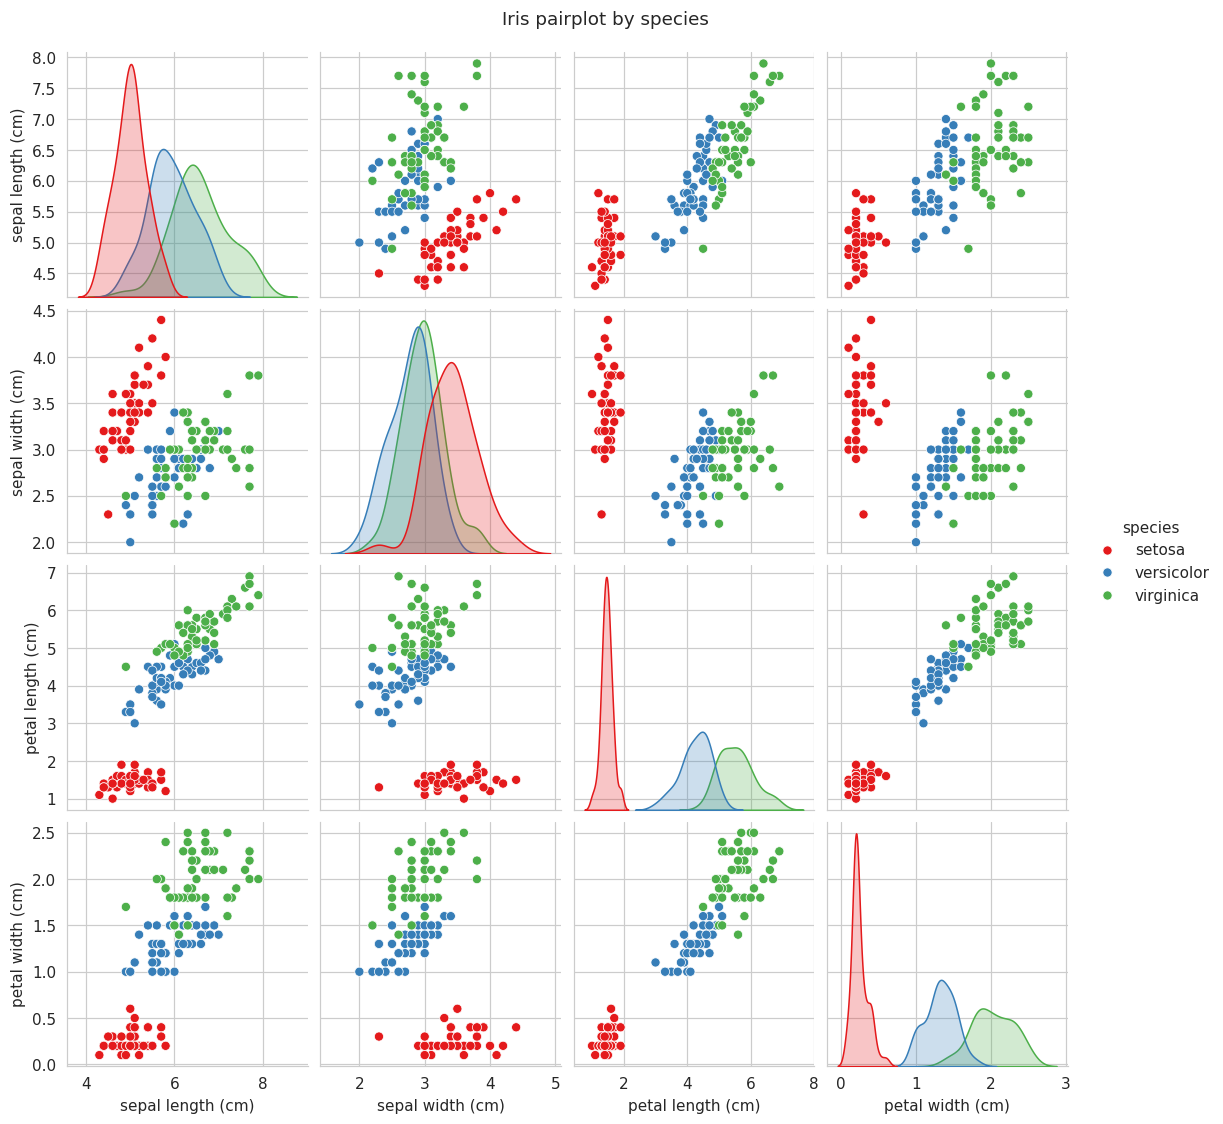

In [3]:
g = sns.pairplot(df.drop(columns='target'), hue='species', palette='Set1')
g.figure.suptitle('Iris pairplot by species', y=1.02)
plt.show()

**Box plots** - the spread of each feature per species.

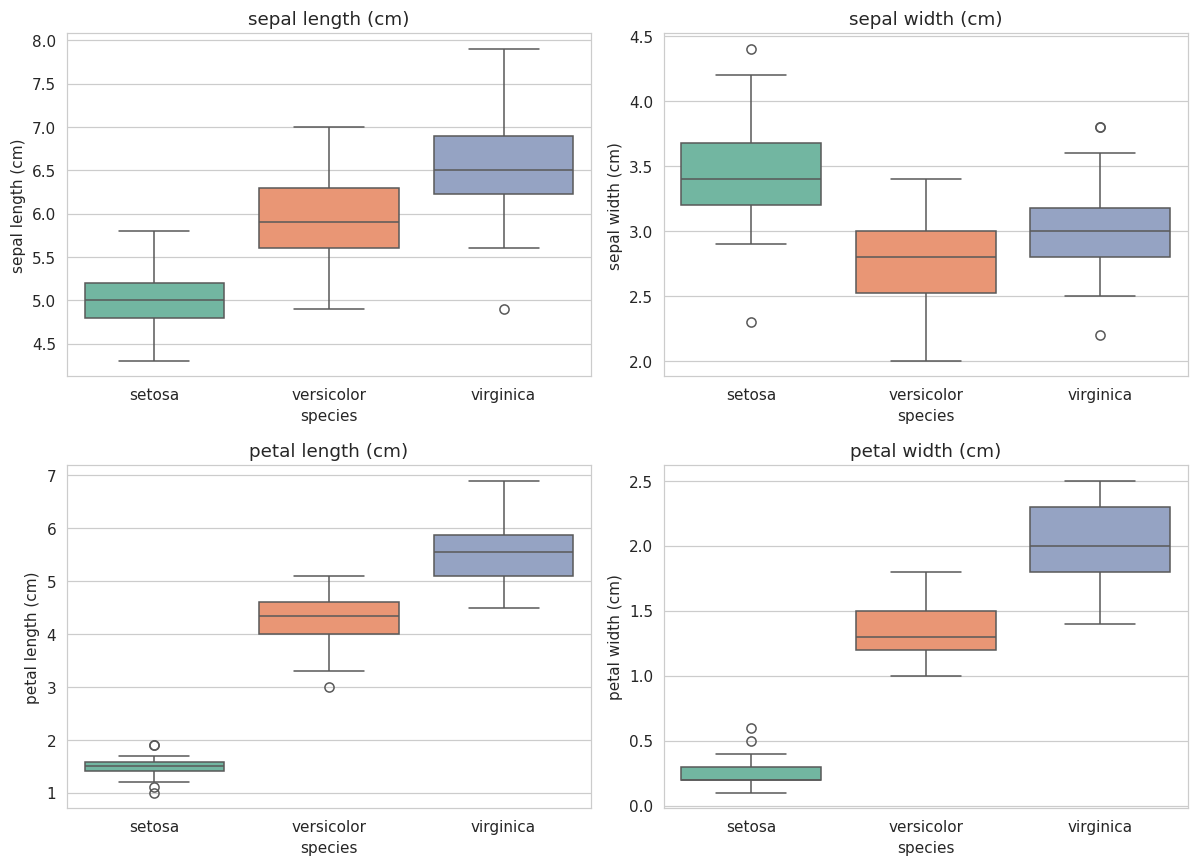

In [4]:
features = iris.feature_names
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x='species', y=col, data=df, hue='species', palette='Set2', legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 4. Feature selection discussion

Mean of each feature per species:
            sepal length (cm)  ...  petal width (cm)
species                        ...                  
setosa                   5.01  ...              0.25
versicolor               5.94  ...              1.33
virginica                6.59  ...              2.03

[3 rows x 4 columns]


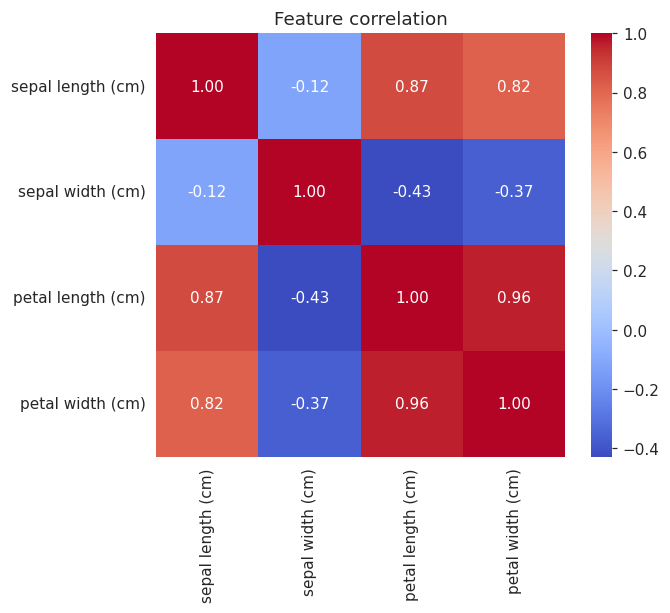

In [5]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature correlation')
plt.show()
print('Mean of each feature per species:')
print(df.groupby('species')[features].mean().round(2))

**Which features discriminate best?** Petal length and petal width separate the three species far better than sepal length and sepal width. Setosa is completely separable using the petal measurements alone, while Versicolor and Virginica overlap slightly. The sepal width is the weakest feature because the species overlap heavily on it. We still keep all four features, since the dataset is small and the extra features can only help.

## 5. Train / test split (80 / 20)

In [6]:
X = df[features]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps class balance equal
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (120, 4)  Test: (30, 4)


## 6. Train the classifiers

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


## 7. Evaluate each model
Accuracy, confusion matrix and classification report (precision, recall, F1).

Logistic Regression
Test accuracy: 0.9667 | 5-fold CV accuracy: 0.9733
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

K-Nearest Neighbours
Test accuracy: 1.0 | 5-fold CV accuracy: 0.9733
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Decision Tree
Test accuracy: 0.9333 | 5-fold CV accuracy: 0.9533
              precision    recall

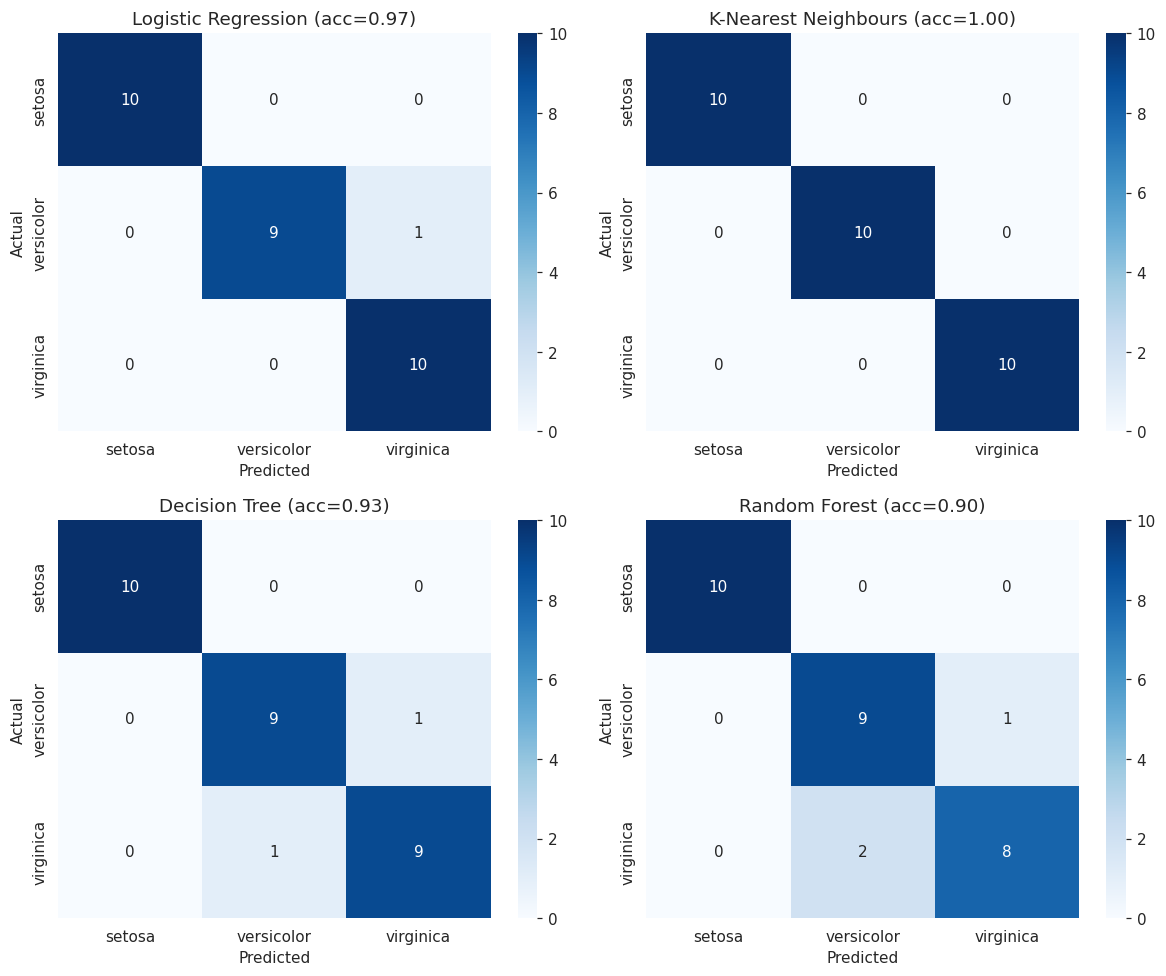

In [8]:
results = {}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    cv = cross_val_score(model, X, y, cv=5).mean()
    results[name] = {'test_accuracy': acc, 'cv_accuracy': cv}
    print('=' * 60)
    print(name)
    print('Test accuracy:', round(acc, 4), '| 5-fold CV accuracy:', round(cv, 4))
    print(classification_report(y_test, pred, target_names=iris.target_names))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax)
    ax.set_title(f'{name} (acc={acc:.2f})'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

## 8. Compare models and pick the best one

                      test_accuracy  cv_accuracy
Logistic Regression          0.9667       0.9733
K-Nearest Neighbours         1.0000       0.9733
Decision Tree                0.9333       0.9533
Random Forest                0.9000       0.9667

Best model: K-Nearest Neighbours


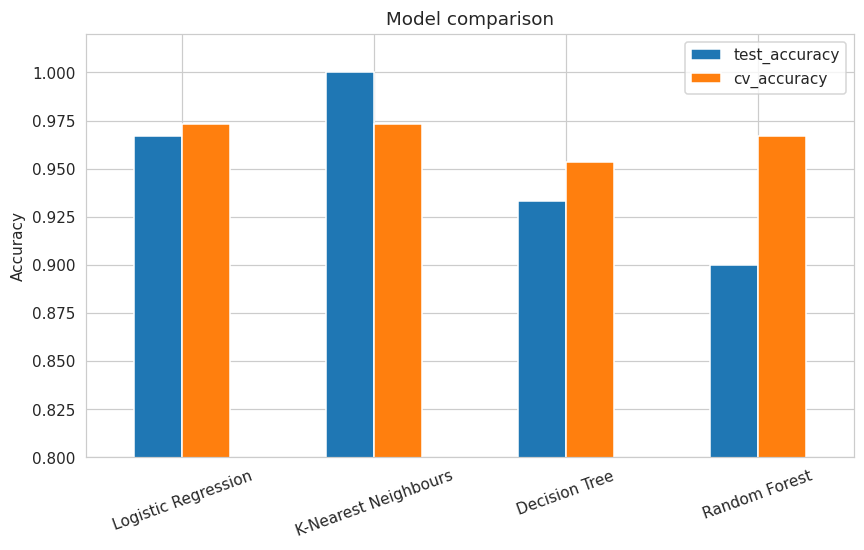

In [9]:
summary = pd.DataFrame(results).T.round(4)
print(summary)
best = summary.sort_values(['cv_accuracy', 'test_accuracy'], ascending=False).index[0]
print('\nBest model:', best)
summary.plot(kind='bar', figsize=(9, 5), ylim=(0.8, 1.02))
plt.title('Model comparison'); plt.ylabel('Accuracy'); plt.xticks(rotation=20)
plt.show()

## 9. Conclusion
**Best model: K-Nearest Neighbours**

- Test accuracy: 1.0000, 5-fold cross-validated accuracy: 0.9733.
- The model was chosen on cross-validated accuracy, with test accuracy as tie-breaker. The test set has only 30 flowers, so one mistake changes accuracy by 3%, and cross-validation gives a more reliable ranking.
- Almost all errors involve Versicolor vs Virginica; Setosa is always classified correctly.
- Petal length and petal width are the most useful features.